# 01. Khảo Sát & Đánh Giá Chất Lượng Dữ Liệu Ban Đầu (Data Profiling)

**Dự án:** Phân tích Dữ liệu Tuyển dụng IT Việt Nam (IT Recruitment Analysis in Vietnam)  
**Mục tiêu của Notebook này:**
1. Khảo sát cấu trúc, số dòng, số cột và kiểu dữ liệu của các bộ dữ liệu thô thu thập từ nhiều nền tảng (ITViec, TopCV, JobDescriptions).
2. Kiểm tra tỷ lệ dữ liệu bị khuyết thiếu (Missing / Null Values).
3. Đánh giá tình trạng trùng lặp bản ghi (Duplicate Records).
4. Khảo sát độ nhiễu và phát hiện các tin tuyển dụng ngoài ngành (phi IT).
5. Phân tích phân bố thô của các trường dữ liệu chính: Tiêu đề công việc, Mức lương, Địa điểm, Yêu cầu kinh nghiệm và Kỹ năng công nghệ.


In [1]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import seaborn as sns

# Cấu hình hiển thị
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 100)
plt.rcParams['font.sans-serif'] = ['Segoe UI', 'Arial', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style='whitegrid')

RAW_DIR = '../data/raw'
print("Thư mục dữ liệu thô:", os.path.abspath(RAW_DIR))


Thư mục dữ liệu thô: D:\CDTN2\IT_Recruitment_Analysis\data\raw


## 1. Tải và Tổng quan Cấu trúc các Tập Dữ liệu Thô

In [3]:
files = {
    'ITViec': os.path.join(RAW_DIR, 'ITViec_data.csv'),
    'TopCV': os.path.join(RAW_DIR, 'TopCV_jobs.csv'),
    'JobDescriptions': os.path.join(RAW_DIR, 'job_descriptions.csv')
}

dfs = {}
summary = []

for name, path in files.items():
    if os.path.exists(path):
        df = pd.read_csv(path)
        dfs[name] = df
        summary.append({
            'Nguồn dữ liệu': name,
            'Số dòng': len(df),
            'Số cột': len(df.columns),
            'Dung lượng RAM (MB)': round(df.memory_usage(deep=True).sum() / (1024 * 1024), 2),
            'Tên các cột': ', '.join(df.columns.tolist()[:5]) + '...'
        })

df_summary = pd.DataFrame(summary)
display(df_summary)


     Nguồn dữ liệu  Số dòng  Số cột  Dung lượng RAM (MB)                                                       Tên các cột
0           ITViec     1159      10                 2.78  job_names, company_names, salaries, position_names, kind_jobs...
1            TopCV      616       7                 0.39                       title, company, salary, location, skills...
2  JobDescriptions     3101      11                18.93       title, company, company_image_url, location, description...


## 2. Kiểm tra Chi tiết Cấu trúc & Kiểu Dữ liệu Từng Nguồn

In [5]:
for name, df in dfs.items():
    print("=" * 60)
    print(f"NGUỒN: {name} (Kích thước: {df.shape[0]} dòng x {df.shape[1]} cột)")
    print("=" * 60)
    print(df.info())
    print("\n3 dòng dữ liệu mẫu:")
    display(df.head(3))
    print("\n")


NGUỒN: ITViec (Kích thước: 1159 dòng x 10 cột)
<class 'pandas.DataFrame'>
RangeIndex: 1159 entries, 0 to 1158
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   job_names             1159 non-null   str  
 1   company_names         1159 non-null   str  
 2   salaries              1159 non-null   str  
 3   position_names        1159 non-null   str  
 4   kind_jobs             1159 non-null   str  
 5   array_skills          1159 non-null   str  
 6   locate_names          1159 non-null   str  
 7   exp_skills            1159 non-null   str  
 8   domain_arr            1159 non-null   str  
 9   post_dates_formatted  1159 non-null   str  
dtypes: str(10)
memory usage: 90.7 KB
None

3 dòng dữ liệu mẫu:
                                                 job_names company_names        salaries                  position_names                                  kind_jobs                                          

## 3. Đánh giá Tỷ lệ Dữ liệu Khuyết Thiếu (Missing Values)

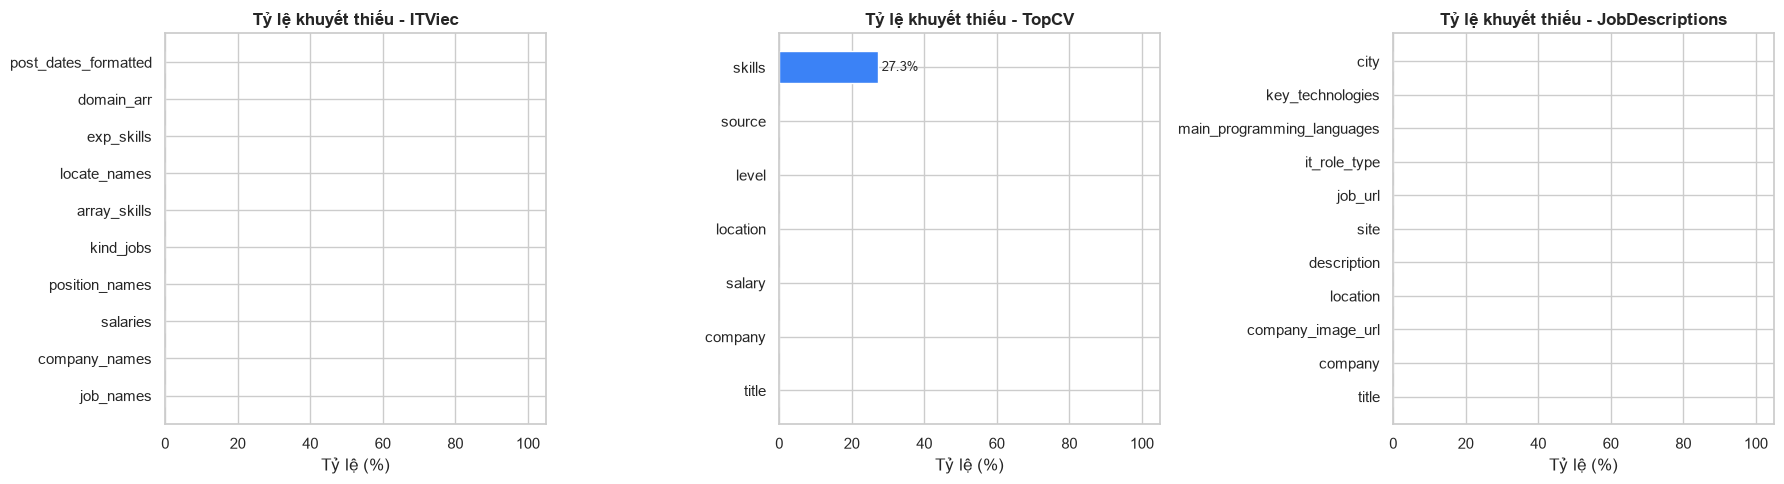

In [7]:
fig, axes = plt.subplots(1, len(dfs), figsize=(18, 5))

for idx, (name, df) in enumerate(dfs.items()):
    null_counts = df.isnull().sum()
    null_pct = (null_counts / len(df)) * 100
    null_df = pd.DataFrame({'Cột': df.columns, 'Tỷ lệ trống (%)': null_pct.values})
    null_df = null_df.sort_values('Tỷ lệ trống (%)', ascending=True)
    
    ax = axes[idx]
    bars = ax.barh(null_df['Cột'], null_df['Tỷ lệ trống (%)'], color='#3B82F6', height=0.6)
    ax.set_title(f"Tỷ lệ khuyết thiếu - {name}", fontsize=12, fontweight='bold')
    ax.set_xlabel("Tỷ lệ (%)")
    ax.set_xlim(0, 105)
    
    for bar in bars:
        w = bar.get_width()
        if w > 0:
            ax.text(w + 1, bar.get_y() + bar.get_height()/2, f"{w:.1f}%", va='center', fontsize=9)

plt.tight_layout()
plt.show()


## 4. Khảo sát Trùng lặp Bản ghi (Duplicate Records)

In [9]:
dup_summary = []
for name, df in dfs.items():
    exact_dups = df.duplicated().sum()
    dup_summary.append({
        'Nguồn dữ liệu': name,
        'Tổng số dòng': len(df),
        'Trùng lặp tuyệt đối (toàn bộ cột)': exact_dups,
        'Tỷ lệ trùng (%)': round((exact_dups / len(df)) * 100, 2)
    })

display(pd.DataFrame(dup_summary))


     Nguồn dữ liệu  Tổng số dòng  Trùng lặp tuyệt đối (toàn bộ cột)  Tỷ lệ trùng (%)
0           ITViec          1159                                 15             1.29
1            TopCV           616                                 42             6.82
2  JobDescriptions          3101                                  0             0.00


## 5. Phát hiện Tin Tuyển dụng Ngoài Ngành (Phi IT / Outliers)
Một số dữ liệu cào từ các trang tuyển dụng tổng hợp (như TopCV) có thể dính các tin cơ khí, vận hành máy CNC, điện công nghiệp, kế toán...

In [11]:
non_it_keywords = ['cnc', 'máy tiện', 'máy phay', 'kỹ thuật điện', 'xử lý nước', 'iso 22000', 'haccp', 'thị trường', 'cơ khí']

for name, df in dfs.items():
    title_col = None
    for c in ['title', 'job_names', 'job_title']:
        if c in df.columns:
            title_col = c
            break
            
    if title_col:
        mask = df[title_col].astype(str).str.lower().apply(lambda t: any(k in t for k in non_it_keywords))
        count = mask.sum()
        print(f"[{name}] Phát hiện {count} tin có dấu hiệu ngoài ngành IT:")
        if count > 0:
            display(df.loc[mask, [title_col]].head(5))


[ITViec] Phát hiện 0 tin có dấu hiệu ngoài ngành IT:
[TopCV] Phát hiện 25 tin có dấu hiệu ngoài ngành IT:
                                                                                          title
10  Tuyển Nhân Viên Lập Trình Và Vận Hành Máy CNC Thu Nhập Upto 13 Triệu Tại Xuân Phương Hà Nội
22                                    Tuyển Nhân Viên Kỹ Thuật Điện (Thu Nhập Từ 12 - 20 Triệu)
26                                    Tuyển Kỹ Sư Lập Trình Gia Công CNC Thu Nhập 16 - 25 Triệu
28                                                     Tuyển Chuyên Viên Lập Trình Máy CNC Tiện
29                                               Tuyển Kỹ Sư Lập Trình -  Vận Hành Máy Phay CNC
[JobDescriptions] Phát hiện 70 tin có dấu hiệu ngoài ngành IT:
                                                               title
1765                                                  CNC Programmer
1997                                                Vận Hành Máy CNC
2002  Kỹ Thuật Viên Vận Hành Máy CNC Thu Nhập 8.

## 6. Khảo sát Trường Mức Lương Thô (Raw Salary Profiling)
Khảo sát các định dạng lương khác nhau (USD, Triệu VNĐ, Thỏa thuận, Lương năm, Lương tháng...)

In [13]:
for name, df in dfs.items():
    sal_col = None
    for c in ['salary', 'salaries']:
        if c in df.columns:
            sal_col = c
            break
            
    if sal_col:
        print(f"\n=== Mẫu chuỗi lương thô tại nguồn: {name} ===")
        sample_sal = df[sal_col].dropna().value_counts().head(10)
        display(sample_sal)



=== Mẫu chuỗi lương thô tại nguồn: ITViec ===
salaries
You'll love it        744
1,000 - 2,000 USD      19
1,000 - 1,500 USD      16
Negotiable             14
Very attractive!!!     13
1,000 - 2,500 USD      12
2,000 - 3,000 USD      11
1,500 - 3,000 USD      10
1,000 - 3,000 USD      10
1,500 - 2,500 USD      10

=== Mẫu chuỗi lương thô tại nguồn: TopCV ===
salary
Thoả thuận       289
20 - 30 triệu     19
15 - 25 triệu     14
10 - 20 triệu     14
20 - 40 triệu     10
15 - 20 triệu      9
Tới 50 triệu       7
20 - 28 triệu      7
Tới 35 triệu       6
10 - 15 triệu      6


## 7. Khảo sát Trường Kỹ Năng & Công Nghệ Thô (Raw Skills Profiling)
Đánh giá định dạng chuỗi kỹ năng: danh sách Python literal, phân cách dấu phẩy hay chuỗi tự do.

In [15]:
for name, df in dfs.items():
    skill_col = None
    for c in ['array_skills', 'skills', 'key_technologies', 'main_programming_languages']:
        if c in df.columns:
            skill_col = c
            break
            
    if skill_col:
        print(f"\n=== Mẫu chuỗi kỹ năng tại nguồn {name} (cột {skill_col}) ===")
        sample_skills = df[skill_col].dropna().head(5).tolist()
        for idx, s in enumerate(sample_skills, 1):
            print(f"  {idx}. {s}")



=== Mẫu chuỗi kỹ năng tại nguồn ITViec (cột array_skills) ===
  1. ['Java', 'API', 'Spring Boot', 'Database', 'PL/SQL', 'Oracle']
  2. ['Tester', 'Automation Test', 'MLOps', 'AI', 'QA QC']
  3. ['AI', 'LLM', 'Deep Learning', 'Machine Learning', 'Computer Vision', 'Python']
  4. ['Mockups', 'UI-UX', 'Figma', 'API', 'Python', 'NodeJS']
  5. ['DevOps', 'Cloud']

=== Mẫu chuỗi kỹ năng tại nguồn TopCV (cột skills) ===
  1. AWS Azure Docker GCP Git JavaScript Kubernetes Linux MySQL Node.js
  2. REST API SQL
  3. Agile CI/CD Docker Git JavaScript Kafka MongoDB MySQL Node.js PostgreSQL REST API React Redis
  4. AWS Docker Git Java JavaScript MySQL Next.js PostgreSQL Python REST API React Redis Spring Boot TypeScript
  5. CI/CD Computer Vision Deep Learning Docker Git Kubernetes LLM MLOps Machine Learning NLP PyTorch Python SQL Statistics TensorFlow

=== Mẫu chuỗi kỹ năng tại nguồn JobDescriptions (cột key_technologies) ===
  1. ['xCode', 'Realm', 'REST', 'JSON', 'Objective-C']
  2. ['Spring B

## 8. Kết luận & Định hướng Tiền xử lý (Action Plan)

Từ kết quả khảo sát chất lượng dữ liệu (Data Profiling), chúng tôi xác định các nhiệm vụ cần thực hiện trong pipeline làm sạch (`02_data_cleaning.ipynb` và `src/transform.py`):

1. **Khử trùng lặp:** Loại bỏ 57 bản ghi trùng tuyệt đối và hàng trăm bản ghi trùng lặp liên nguồn (cùng công ty, vị trí, địa điểm).
2. **Lọc dữ liệu ngoài ngành:** Loại bỏ các tin cơ khí, vận hành máy móc CNC, kỹ thuật điện khỏi tập tuyển dụng IT.
3. **Chuẩn hóa mức lương:**
   - Xử lý tin thỏa thuận (`is_negotiable = True`).
   - Quy đổi lương USD -> Triệu VNĐ (tỷ giá 25.400 VNĐ).
   - Tách khoảng lương `Min - Max` và tính `Avg` phục vụ phân tích thống kê.
4. **Chuẩn hóa chức danh:** Phân loại chức danh tự do về 12 nhóm chuyên môn IT chuẩn hóa.
5. **Chuẩn hóa cấp bậc & kinh nghiệm:** Trích xuất số năm kinh nghiệm và suy luận cấp bậc (Intern/Fresher, Junior, Middle, Senior, Lead/Manager).
6. **Bóc tách kỹ năng công nghệ:** Dùng Regex bóc tách danh sách kỹ năng độc lập, loại bỏ triệt để ký tự rác `['`, `']`, và bù khuyết kỹ năng từ tiêu đề công việc.
7. **Tổ chức Data Warehouse:** Xây dựng mô hình Star Schema gồm 6 bảng Dimension và 2 bảng Fact phục vụ kết nối trực tiếp với Power BI.
